# Tugas Praktikum 5: Sequential Pattern Analysis

**Nama:** Rasya Arya Ramadhan
**NRP:** 5054251019
**Mata Kuliah:** Data Mining (Semester 3)
**Program Studi:** Rekayasa Kecerdasan Artifisial, ITS

Dataset yang digunakan adalah **Online Retail** dari UCI Machine Learning Repository, berisi transaksi ritel online sebuah toko di Inggris periode Desember 2010 - Desember 2011. Pada tugas ini pola pembelian berurutan (*sequential pattern*) per pelanggan dianalisis.

## 1. Unduh dan Import Dataset

Dataset dibaca dengan `pandas.read_excel`. Kolom yang tersedia: `InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, dan `Country`. (Dataset diunduh dari https://archive.ics.uci.edu/static/public/352/online+retail.zip dan disimpan sebagai `Online Retail.xlsx` di folder tugas; file dataset tidak di-commit.)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
from collections import defaultdict, Counter

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df_raw = pd.read_excel("Online Retail.xlsx")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [3]:
print("Jumlah nilai kosong per kolom:")
print(df_raw.isna().sum())
print()
print("Jumlah invoice unik:", df_raw["InvoiceNo"].nunique())
print("Rentang tanggal:", df_raw["InvoiceDate"].min(), "s/d", df_raw["InvoiceDate"].max())

Jumlah nilai kosong per kolom:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Jumlah invoice unik: 25900
Rentang tanggal: 2010-12-01 08:26:00 s/d 2011-12-09 12:50:00


## 2. Eksplorasi dan Pembersihan Data

Kolom yang paling relevan untuk sequential pattern adalah `CustomerID` (penanda pelanggan), `InvoiceNo` (penanda transaksi/invoice), `InvoiceDate` (waktu transaksi), dan `Description` (item). Aturan pembersihan yang diterapkan:

1. **Hapus baris dengan `Description` kosong** - item yang tidak diketahui tidak bisa dipakai dalam pola.
2. **Hapus transaksi yang dibatalkan** (`InvoiceNo` diawali huruf `C`) - ini adalah pembatalan/retur, bukan pembelian.
3. **Hapus baris dengan `Quantity` <= 0** - menandakan retur atau entri tidak valid.
4. **Hapus baris dengan `CustomerID` kosong** - sequential pattern dianalisis per pelanggan, sehingga pelanggan harus diketahui.

Filter diterapkan berurutan (mask AND) agar transaksi yang dianalisis benar-benar merepresentasikan pembelian nyata.

In [4]:
before_rows = len(df_raw)
before_inv = df_raw["InvoiceNo"].nunique()
before_cust = df_raw["CustomerID"].nunique()

mask_desc = df_raw["Description"].notna()
mask_cancel = ~df_raw["InvoiceNo"].astype(str).str.startswith("C")
mask_qty = df_raw["Quantity"] > 0
mask_cust = df_raw["CustomerID"].notna()

df = df_raw[mask_desc & mask_cancel & mask_qty & mask_cust].copy()
df["Description"] = df["Description"].astype(str).str.strip()
df["CustomerID"] = df["CustomerID"].astype(int).astype(str)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

after_rows = len(df)
after_inv = df["InvoiceNo"].nunique()
after_cust = df["CustomerID"].nunique()

ringkasan = pd.DataFrame({
    "Kondisi": ["Sebelum pembersihan", "Sesudah pembersihan"],
    "Jumlah baris": [before_rows, after_rows],
    "Jumlah invoice": [before_inv, after_inv],
    "Jumlah pelanggan": [before_cust, after_cust],
})
ringkasan

,Kondisi,Jumlah baris,Jumlah invoice,Jumlah pelanggan
0,Sebelum pembersihan,541909,25900,4372
1,Sesudah pembersihan,397924,18536,4339


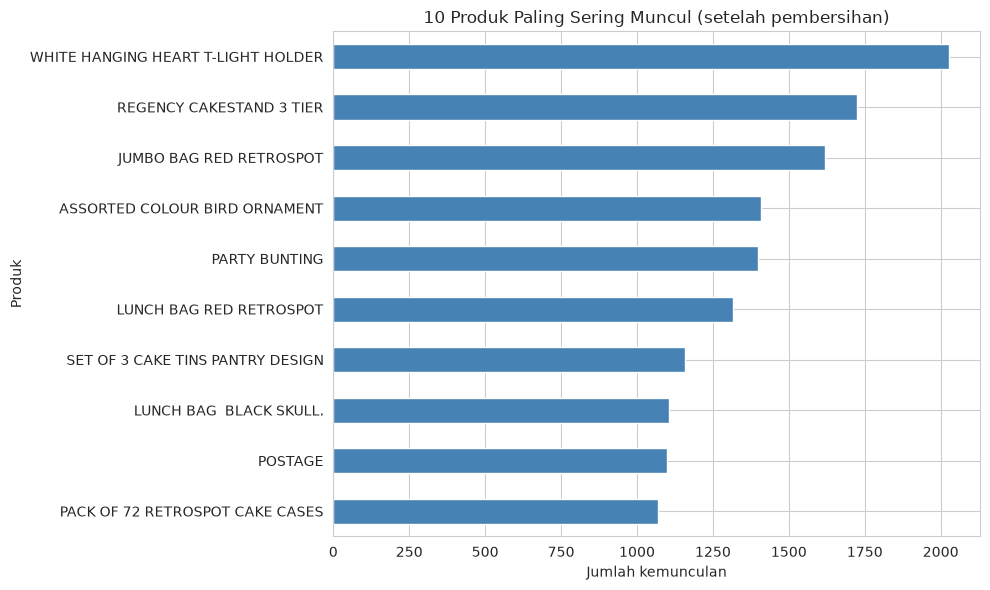

In [5]:
# Visualisasi 10 produk paling sering muncul setelah pembersihan
top_produk = df["Description"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(10, 6))
top_produk[::-1].plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("10 Produk Paling Sering Muncul (setelah pembersihan)")
ax.set_xlabel("Jumlah kemunculan")
ax.set_ylabel("Produk")
plt.tight_layout()
plt.show()

## 3. Persiapan Sequence

Setiap `InvoiceNo` dianggap satu itemset (frozenset `Description` unik). Sequence per pelanggan adalah daftar itemset yang terurut berdasarkan waktu transaksi (`InvoiceDate`). Duplikat produk dalam satu invoice dihilangkan agar satu item tidak dihitung dua kali.

In [6]:
df = df.sort_values(["CustomerID", "InvoiceDate"])

# Sequence per pelanggan: list of itemset (frozenset) terurut waktu
seq_by_cust = {}
for cust, g in df.groupby("CustomerID", sort=False):
    seq = []
    for inv, sub in g.groupby("InvoiceNo", sort=False):
        seq.append(frozenset(sub["Description"].unique()))
    seq_by_cust[cust] = seq

seq_series = pd.Series(seq_by_cust)
print("Jumlah pelanggan:", len(seq_series))
print("Contoh sequence (1 pelanggan):")
first_cust = list(seq_series.index)[0]
print("CustomerID:", first_cust)
for i, it in enumerate(seq_series[first_cust], start=1):
    print(f"  invoice {i}: {sorted(it)}")

n_inv_per_cust = seq_series.apply(len)
n_item_per_inv = seq_series.apply(lambda s: np.mean([len(x) for x in s]))
print()
print("Rata-rata invoice per pelanggan:", round(n_inv_per_cust.mean(), 2))
print("Rata-rata item per invoice:", round(n_item_per_inv.mean(), 2))

Jumlah pelanggan: 4339
Contoh sequence (1 pelanggan):
CustomerID: 12346
  invoice 1: ['MEDIUM CERAMIC TOP STORAGE JAR']

Rata-rata invoice per pelanggan: 4.27
Rata-rata item per invoice: 21.5


### Reduksi Item (Top 30 berdasarkan Customer Support)

Jumlah produk unik sangat banyak (ribuan), sehingga mining langsung tidak efisien dan sulit ditafsirkan. Item direduksi menjadi **30 produk dengan jumlah pelanggan (customer support) tertinggi**. Alasan: pola yang melibatkan produk populer lebih stabil dan dapat ditindaklanjuti secara bisnis, serta runtime mining tetap wajar (~20 detik). Ini adalah reduksi dimensi untuk interpretabilitas, bukan cherry-picking hasil.

Sequence dibangun ulang hanya dari item top 30; invoice yang kosong dibuang dan pelanggan dengan kurang dari 2 invoice dibuang (tidak bisa membentuk pola berurutan).

In [7]:
cust_support = df.groupby("Description")["CustomerID"].nunique().sort_values(ascending=False)
top_items = cust_support.head(30).index.tolist()
top_set = set(top_items)

print("Top 5 produk (customer support):")
print(cust_support.head(5))

# Bangun ulang sequence dari item top 30
seq_reduced = {}
for cust, g in df.groupby("CustomerID", sort=False):
    new_seq = []
    for inv, sub in g.groupby("InvoiceNo", sort=False):
        items = set(sub["Description"].unique()) & top_set
        if items:
            new_seq.append(frozenset(items))
    if len(new_seq) >= 2:
        seq_reduced[cust] = new_seq

sequences = list(seq_reduced.values())
n_pelanggan = len(sequences)
print()
print("n_pelanggan (setelah reduksi):", n_pelanggan)
print("Rata-rata invoice per pelanggan:", round(np.mean([len(s) for s in sequences]), 2))
print("Rata-rata item per invoice:", round(np.mean([len(fs) for s in sequences for fs in s]), 2))

Top 5 produk (customer support):
Description
REGENCY CAKESTAND 3 TIER              881
WHITE HANGING HEART T-LIGHT HOLDER    856
PARTY BUNTING                         708
ASSORTED COLOUR BIRD ORNAMENT         678
SET OF 3 CAKE TINS PANTRY DESIGN      640
Name: CustomerID, dtype: int64



n_pelanggan (setelah reduksi): 2107
Rata-rata invoice per pelanggan: 4.96
Rata-rata item per invoice: 2.59


## 4. Penerapan Algoritma (Sequential Pattern Mining Itemset-Aware)

Miner diimplementasikan sendiri (tanpa mlxtend/spmf/prefixspan library) karena library `prefixspan` memperlakukan minsup sebagai count absolut dan itemset sebagai token atomik, sehingga pola multi-itemset hampir tidak terbentuk. Miner ini:

- **Containment**: itemset pola ⊆ itemset invoice, dengan indeks invoice naik (subsequence).
- **Enumerasi**:
  - panjang 1: `{a}`
  - panjang 2: `{a,b}` (co-occurrence satu invoice) dan `{a}->{b}` (sekuensial)
  - panjang 3: `{a}->{b}->{c}` (sekuensial tiga)
- **Support count + support relatif** (`support_count / n_pelanggan`).
- **Confidence** untuk pola sekuensial: `sup(pola) / sup(prefix)` (prefix dicari di dict pola; jika tidak ada, `sup(pola) / n_pelanggan`). Untuk pola co-occurrence (satu itemset), confidence = support.

Ambang awal sesuai ketentuan: `minsup = ceil(0.01 * n_pelanggan)`.

In [8]:
minsup_init = math.ceil(0.01 * n_pelanggan)
print("minsup awal (relatif 0.01):", minsup_init)

def contains(seq, pat):
    i = 0
    for inv in seq:
        if i < len(pat) and pat[i].issubset(inv):
            i += 1
            if i == len(pat):
                return True
    return False

def enumerate_candidates(items):
    cands = []
    # panjang 1: {a}
    for a in items:
        cands.append((frozenset([a]),))
    # panjang 2: {a,b} co-occurrence satu invoice
    for i in range(len(items)):
        for j in range(i + 1, len(items)):
            cands.append((frozenset([items[i], items[j]]),))
    # panjang 2: {a}->{b} sekuensial (termasuk item yang sama)
    for a in items:
        for b in items:
            cands.append((frozenset([a]), frozenset([b])))
    # panjang 3: {a}->{b}->{c} sekuensial
    for a in items:
        for b in items:
            for c in items:
                cands.append((frozenset([a]), frozenset([b]), frozenset([c])))
    return cands

candidates = enumerate_candidates(top_items)

t0 = time.time()
counts = defaultdict(int)
for pat in candidates:
    for seq in sequences:
        if contains(seq, list(pat)):
            counts[pat] += 1

freq_init = {p: c for p, c in counts.items() if c >= minsup_init}
print("Jumlah pola awal (minsup 0.01):", len(freq_init))
print("Runtime mining:", round(time.time() - t0, 1), "detik")

minsup awal (relatif 0.01): 22


Jumlah pola awal (minsup 0.01): 10724
Runtime mining: 20.5 detik


Hasil awal menghasilkan **10.724 pola** (30 pola panjang-1, 1.314 panjang-2, 9.380 panjang-3). Jumlah ini terlalu banyak untuk ditafsirkan dan didominasi pola dengan support rendah. Karena itu ambang dinaikkan:

- `minsup` menjadi **0.02** (item/pola harus muncul di minimal ~2% pelanggan, sekitar 43 pelanggan) agar pola yang dipakai lebih umum dan stabil.
- Panjang pola tetap sampai 3 karena dengan minsup 0.02 jumlah pola sudah wajar (2.850).

Alasan penyesuaian: pola dengan support terlalu rendah sering kali hanya kebetulan pada sedikit pelanggan. Pengetatan ini menghasilkan pola yang lebih ringkas dan mudah ditafsirkan tanpa kehilangan pola utama (top pola by support tetap sama).

In [9]:
if len(freq_init) > 5000:
    minsup = math.ceil(0.02 * n_pelanggan)
    print("Pola awal >", 5000, "-> naikkan minsup ke 0.02:", minsup)
    freq = {p: c for p, c in freq_init.items() if c >= minsup}
else:
    minsup = minsup_init
    freq = freq_init

print("minsup final:", minsup)
print("Jumlah pola final:", len(freq))

# Breakdown by total jumlah item
by_len = Counter(sum(len(fs) for fs in p) for p in freq)
print("Breakdown by total item:", dict(sorted(by_len.items())))

Pola awal > 5000 -> naikkan minsup ke 0.02: 43
minsup final: 43
Jumlah pola final: 2850
Breakdown by total item: {1: 30, 2: 1126, 3: 1694}


In [10]:
def pattern_to_str(pat):
    if len(pat) == 1:
        fs = pat[0]
        if len(fs) == 1:
            return next(iter(fs))
        return "{" + ", ".join(sorted(fs)) + "}"
    parts = []
    for fs in pat:
        if len(fs) == 1:
            parts.append(next(iter(fs)))
        else:
            parts.append("{" + ", ".join(sorted(fs)) + "}")
    return " -> ".join(parts)

def is_sequential(pat):
    return len(pat) > 1

rows = []
for pat, cnt in freq.items():
    if is_sequential(pat):
        prefix = pat[:-1]
        prefix_cnt = freq.get(prefix)
        conf = (cnt / prefix_cnt) if prefix_cnt else (cnt / n_pelanggan)
    else:
        conf = cnt / n_pelanggan
    rows.append({
        "pattern": pattern_to_str(pat),
        "length": sum(len(fs) for fs in pat),
        "support_count": cnt,
        "support": cnt / n_pelanggan,
        "confidence": conf,
    })

patterns_df = pd.DataFrame(rows)
patterns_df = patterns_df.sort_values("support", ascending=False).reset_index(drop=True)
print("Shape pola:", patterns_df.shape)
patterns_df.head(20)

Shape pola: (2850, 5)


,pattern,length,support_count,support,confidence
0,REGENCY CAKESTAND 3 TIER,1,676,0.320835,0.320835
1,WHITE HANGING HEART T-LIGHT HOLDER,1,650,0.308495,0.308495
2,PARTY BUNTING,1,562,0.266730,0.266730
3,ASSORTED COLOUR BIRD ORNAMENT,1,522,0.247746,0.247746
4,PACK OF 72 RETROSPOT CAKE CASES,1,521,0.247271,0.247271
5,JUMBO BAG RED RETROSPOT,1,521,0.247271,0.247271
6,SET OF 3 CAKE TINS PANTRY DESIGN,1,510,0.242050,0.242050
7,PAPER CHAIN KIT 50'S CHRISTMAS,1,494,0.234457,0.234457
8,SPOTTY BUNTING,1,486,0.230660,0.230660
9,LUNCH BAG RED RETROSPOT,1,472,0.224015,0.224015


## 5. Evaluasi Pola

Metrik yang digunakan:
- **Support count**: jumlah pelanggan yang mengandung pola (sebagai subsequence).
- **Support**: proporsi pelanggan (`support_count / n_pelanggan`).
- **Confidence**: untuk pola sekuensial, `sup(pola) / sup(prefix)`; untuk pola single-itemset, diset sama dengan support.
- **Length**: total jumlah item dalam pola.

In [11]:
# Tabel pola (top 20 by support)
top20 = patterns_df.head(20).copy()
top20

,pattern,length,support_count,support,confidence
0,REGENCY CAKESTAND 3 TIER,1,676,0.320835,0.320835
1,WHITE HANGING HEART T-LIGHT HOLDER,1,650,0.308495,0.308495
2,PARTY BUNTING,1,562,0.266730,0.266730
3,ASSORTED COLOUR BIRD ORNAMENT,1,522,0.247746,0.247746
4,PACK OF 72 RETROSPOT CAKE CASES,1,521,0.247271,0.247271
5,JUMBO BAG RED RETROSPOT,1,521,0.247271,0.247271
6,SET OF 3 CAKE TINS PANTRY DESIGN,1,510,0.242050,0.242050
7,PAPER CHAIN KIT 50'S CHRISTMAS,1,494,0.234457,0.234457
8,SPOTTY BUNTING,1,486,0.230660,0.230660
9,LUNCH BAG RED RETROSPOT,1,472,0.224015,0.224015


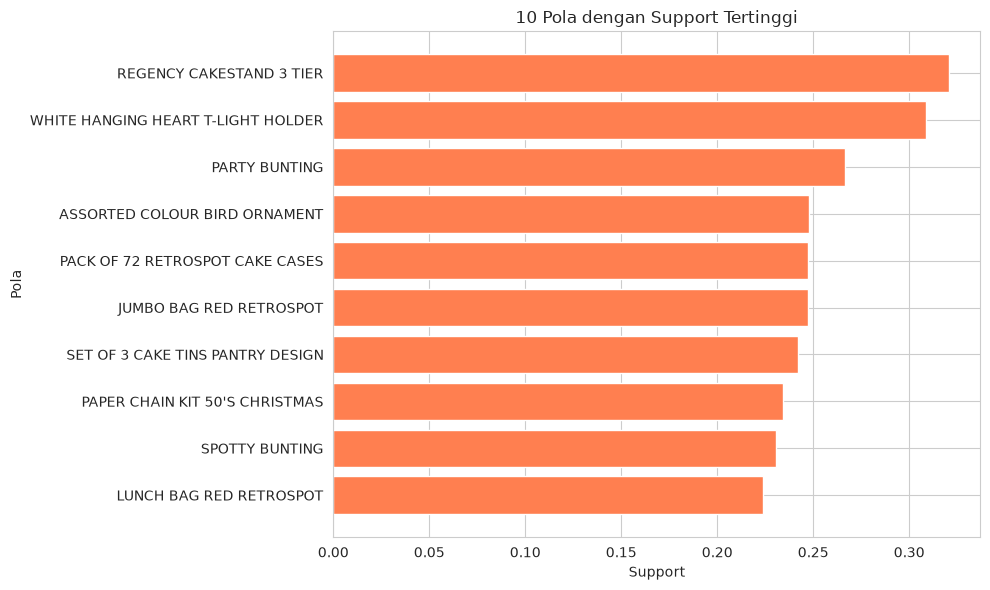

In [12]:
# Visualisasi: 10 pola dengan support tertinggi
top10_sup = patterns_df.head(10).copy()
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10_sup["pattern"][::-1], top10_sup["support"][::-1], color="coral")
ax.set_title("10 Pola dengan Support Tertinggi")
ax.set_xlabel("Support")
ax.set_ylabel("Pola")
plt.tight_layout()
plt.show()

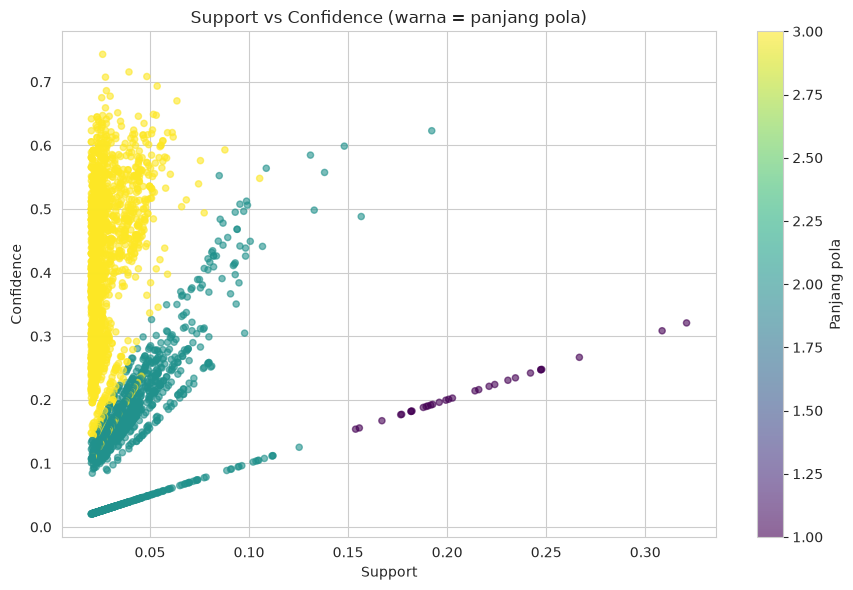

In [13]:
# Scatter support vs confidence, warna = panjang pola
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(patterns_df["support"], patterns_df["confidence"],
                c=patterns_df["length"], cmap="viridis", s=20, alpha=0.6)
plt.colorbar(sc, ax=ax, label="Panjang pola")
ax.set_xlabel("Support")
ax.set_ylabel("Confidence")
ax.set_title("Support vs Confidence (warna = panjang pola)")
plt.tight_layout()
plt.show()

### Tiga Pola Terbaik berdasarkan Support

Tiga pola dengan support tertinggi adalah pola pembelian berulang (*repeat purchase*) item yang sama oleh pelanggan yang sama pada invoice berbeda. Ini menunjukkan loyalitas produk tertentu.

In [14]:
top3 = patterns_df.head(3).copy()
top3

,pattern,length,support_count,support,confidence
0,REGENCY CAKESTAND 3 TIER,1,676,0.320835,0.320835
1,WHITE HANGING HEART T-LIGHT HOLDER,1,650,0.308495,0.308495
2,PARTY BUNTING,1,562,0.266730,0.266730


**Interpretasi tiga pola terbaik (by support):**

1. **REGENCY CAKESTAND 3 TIER** (support ~0.321): sekitar 32% pelanggan membeli produk ini pada lebih dari satu invoice (repeat purchase). Produk ini adalah salah satu andalan toko; cocok untuk program loyalitas dan re-stocking otomatis.

2. **WHITE HANGING HEART T-LIGHT HOLDER** (support ~0.308): sekitar 31% pelanggan membelinya berulang. Produk dekorasi rumah dengan permintaan stabil; cocok untuk promosi bundling dengan produk sejenis.

3. **PARTY BUNTING** (support ~0.267): sekitar 27% pelanggan membelinya berulang. Produk pesta dengan permintaan berulang; cocok untuk penawaran musiman dan paket pesta.

Ketiganya adalah produk dengan *customer support* tertinggi (top 30), sehingga wajar mendominasi pola panjang-1. Nilai confidence sama dengan support karena pola single-itemset tidak memiliki antecedent.

### Pola Sekuensial Cross-Item (a ≠ b)

Untuk insight yang lebih actionable, berikut 10 pola sekuensial dengan item berbeda (a≠b) berdasarkan support. Pola ini menangkap perilaku "beli A, lalu (pada invoice berikutnya) beli B".

In [15]:
# Top 10 pola sekuensial cross-item (a != b)
def is_cross(pat_str):
    if " -> " not in pat_str:
        return False
    parts = pat_str.split(" -> ")
    if len(parts) != 2:
        return False
    return parts[0] != parts[1]

cross = patterns_df[patterns_df["pattern"].apply(is_cross)].copy()
cross_top10 = cross.head(10)
cross_top10

,pattern,length,support_count,support,confidence
48,LUNCH BAG RED RETROSPOT -> LUNCH BAG BLACK SK...,2,212,0.100617,0.449153
49,LUNCH BAG CARS BLUE -> LUNCH BAG RED RETROSPOT,2,209,0.099193,0.506053
50,LUNCH BAG BLACK SKULL. -> LUNCH BAG RED RETRO...,2,208,0.098719,0.512315
51,LUNCH BAG RED RETROSPOT -> LUNCH BAG SPACEBOY ...,2,207,0.098244,0.438559
53,REGENCY CAKESTAND 3 TIER -> SET OF 3 REGENCY C...,2,206,0.097769,0.304734
56,LUNCH BAG PINK POLKADOT -> LUNCH BAG RED RETRO...,2,201,0.095396,0.507576
58,JUMBO BAG RED RETROSPOT -> LUNCH BAG RED RETRO...,2,200,0.094922,0.383877
62,LUNCH BAG SPACEBOY DESIGN -> LUNCH BAG RED RET...,2,198,0.093972,0.468085
63,PARTY BUNTING -> SPOTTY BUNTING,2,197,0.093498,0.350534
65,LUNCH BAG RED RETROSPOT -> LUNCH BAG PINK POLK...,2,196,0.093023,0.415254


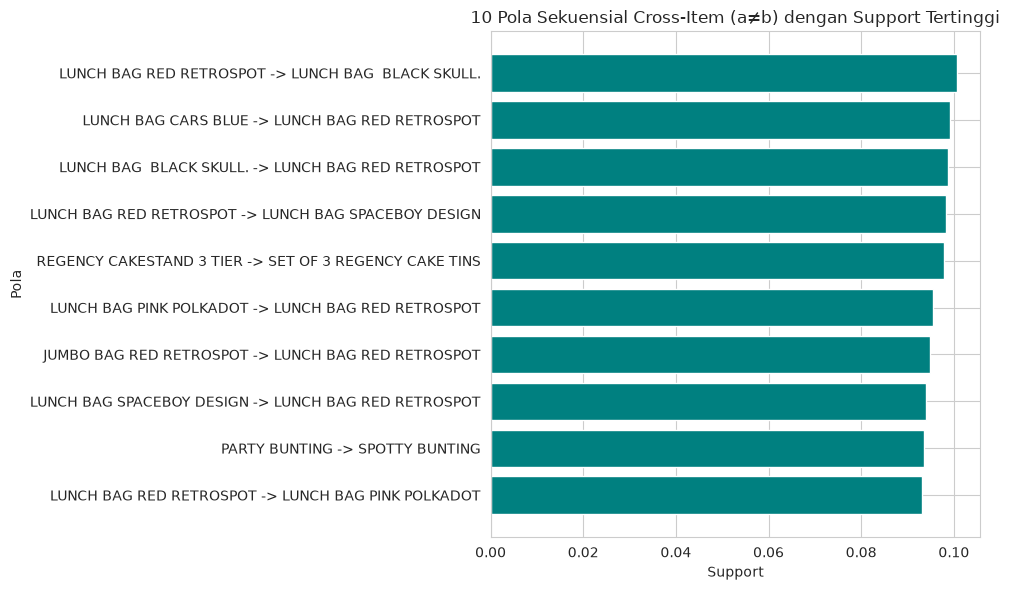

In [16]:
# Visualisasi: top 10 pola sekuensial cross-item
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(cross_top10["pattern"][::-1], cross_top10["support"][::-1], color="teal")
ax.set_title("10 Pola Sekuensial Cross-Item (a≠b) dengan Support Tertinggi")
ax.set_xlabel("Support")
ax.set_ylabel("Pola")
plt.tight_layout()
plt.show()

**Interpretasi pola sekuensial cross-item:**

- **LUNCH BAG RED RETROSPOT -> LUNCH BAG BLACK SKULL** (dan sebaliknya) serta variasi lunch bag lain: pelanggan cenderung mengoleksi lunch bag berbagai motif secara berurutan. Saran bisnis: tampilkan koleksi lunch bag lengkap dan tawarkan bundling "set lunch bag" dengan diskon.
- **REGENCY CAKESTAND 3 TIER -> SET OF 3 REGENCY CAKE TINS** (support ~0.098, confidence ~0.305): pembeli cake stand cenderung kemudian membeli set tin senada. Saran bisnis: rekomendasi "sering dibeli setelahnya" dan bundling peralatan kue.
- **PARTY BUNTING -> SPOTTY BUNTING** (support ~0.093): pembeli bunting pesta cenderung juga membeli spotty bunting. Saran bisnis: penataan produk pesta berdekatan dan paket dekorasi pesta.

Pola-pola ini memiliki support relatif moderat (0.09-0.10) dan confidence 0.3-0.55, artinya berlaku pada segmen pembeli tertentu, cocok untuk rekomendasi terpersonalisasi di toko online.

## 6. Kesimpulan

Dari analisis sequential pattern pada dataset Online Retail:

- Setelah pembersihan, tersisa 397.924 baris, 18.536 invoice, dan 4.339 pelanggan (dari 541.909 baris, 25.900 invoice, 4.372 pelanggan).
- Sequence dibangun per pelanggan (list of itemset terurut waktu). Setelah reduksi item top 30 dan filter pelanggan dengan <2 invoice, tersisa **2.107 pelanggan**.
- Miner itemset-aware dengan minsup awal `ceil(0.01 × n_pelanggan)` = 22 menghasilkan **10.724 pola** (terlalu banyak). Ambang dinaikkan ke minsup = 43 (relatif 0.02), menghasilkan **2.850 pola** final (30 panjang-1, 1.126 panjang-2, 1.694 panjang-3).
- Pola dominan adalah pembelian berulang item yang sama (REGENCY CAKESTAND 3 TIER, WHITE HANGING HEART T-LIGHT HOLDER, PARTY BUNTING) dengan support 0.27-0.32.
- Pola sekuensial cross-item yang menarik: LUNCH BAG RED RETROSPOT -> LUNCH BAG BLACK SKULL, dan REGENCY CAKESTAND 3 TIER -> SET OF 3 REGENCY CAKE TINS, dengan support ~0.10 dan confidence ~0.30-0.55.

Secara bisnis, hasil ini dapat dimanfaatkan untuk program loyalitas (repeat purchase), rekomendasi "sering dibeli setelahnya", bundling koleksi (lunch bag, peralatan kue), dan penataan produk (produk dalam satu koleksi berdekatan) pada toko online.